# 01 — Data and vendor diagnosis (DK1 wind)

**Question.** What does the data look like, and why is the vendor's day-ahead (DA) wind forecast for DK1 biased?

**Data.** Energi Data Service (Energinet): settlement actuals for onshore and offshore wind, and the vendor's
`ForecastDayAhead` and `ForecastCurrent` per technology, hourly, timestamps in UTC. Built into
`data/dk1_hourly.parquet` by `windfc.data`.

| column | meaning |
|---|---|
| `actual_on`, `actual_off`, `actual_total` | settled production, MWh per hour (target = `actual_total`) |
| `da_on`, `da_off`, `da_total` | vendor day-ahead forecast |
| `cur_on`, `cur_off` | vendor `ForecastCurrent` (latest update; used only up to the issue-time cutoff) |

> **Locked test period excluded.** This notebook uses only delivery days **before 2026-05-01**.
> The test period (2026-05-01 → 2026-10-28) is not loaded, plotted or summarised here; it is scored once, in notebook 05.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from windfc.cutoff import delivery_day
from windfc.evaluate import TEST_PERIOD
from windfc.notebook import load_validation
from windfc.run import REPO_ROOT as ROOT

TEST_START = pd.Timestamp(TEST_PERIOD[0])
FIG_DIR = ROOT / "docs" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "lines.linewidth": 1.6, "legend.frameon": False,
})
# Fixed series colours (validated categorical slots 1-3, then neutral ink).
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "ink": "#0b0b0b", "grey": "#8a8984"}

# Validation-only data (windfc.notebook.load_validation): hours whose Danish local
# delivery day is before the locked test period; test rows are filtered while reading.
df = load_validation()
dday = delivery_day(df.index)
assert dday.max() < TEST_START  # also asserted inside load_validation
print(f"hours {df.index.min()} .. {df.index.max()} UTC; delivery days {dday.min().date()} .. {dday.max().date()}")

hours 2021-12-31 23:00:00 .. 2026-04-30 21:00:00 UTC; delivery days 2022-01-01 .. 2026-04-30


## 1. Coverage and missing values

The hourly index is contiguous; source gaps are kept as NaN rather than dropped.

In [2]:
from windfc.cutoff import delivery_hours

expected = delivery_hours(pd.date_range(dday.min(), dday.max(), freq="D"))
print(f"rows {len(df)}, expected hours for these delivery days {len(expected)}, "
      f"index equal: {df.index.equals(expected.as_unit(df.index.unit))}")
nan = pd.DataFrame({"NaN hours": df.isna().sum(), "share %": 100 * df.isna().mean()})
nan

rows 37943, expected hours for these delivery days 37943, index equal: True


,NaN hours,share %
actual_on,0,0.000
actual_off,0,0.000
actual_total,0,0.000
da_on,360,0.949
da_off,336,0.886
da_total,384,1.012
cur_on,166,0.437
cur_off,141,0.372


In [3]:
df.isna().groupby(dday.year).sum().rename_axis("delivery year")

,actual_on,actual_off,actual_total,da_on,da_off,da_total,cur_on,cur_off
delivery year,,,,,,,,
2022,0,0,0,24,24,24,0,0
2023,0,0,0,0,24,24,0,0
2024,0,0,0,120,96,120,57,57
2025,0,0,0,216,192,216,109,84
2026,0,0,0,0,0,0,0,0


Actuals are complete for the validation-era data. Vendor DA values are missing for 384 total-DA hours (about 1%);
these hours are excluded from scoring by the runner's common evaluation mask, identically for every model.

## 2. The vendor does not cover new offshore capacity

If the vendor's offshore model knew the installed capacity, the highest forecast hours would track the highest
actual hours. Quarterly mean and maximum hourly offshore output (grouped by Danish local delivery day):

In [4]:
q = dday.to_period("Q")
off = df[["actual_off", "cur_off", "da_off"]].groupby(q).agg(["mean", "max"]).round(0)
off.index = [f"{p}{' (Apr only)' if str(p) == '2026Q2' else ''}" for p in off.index]
off

actual_off         cur_off         da_off        
                        mean     max    mean     max   mean     max
2022Q1                 741.0  1235.0   685.0  1141.0  698.0  1131.0
2022Q2                 435.0  1227.0   401.0  1117.0  418.0  1064.0
2022Q3                 480.0  1230.0   443.0  1137.0  439.0  1093.0
2022Q4                 732.0  1250.0   678.0  1152.0  697.0  1147.0
2023Q1                 675.0  1224.0   628.0  1156.0  636.0  1141.0
2023Q2                 427.0  1223.0   400.0  1142.0  408.0  1115.0
2023Q3                 430.0  1188.0   412.0  1118.0  459.0  1122.0
2023Q4                 706.0  1330.0   636.0  1135.0  662.0  1051.0
2024Q1                 868.0  1502.0   699.0  1114.0  683.0  1021.0
2024Q2                 610.0  1539.0   443.0  1110.0  512.0  1002.0
2024Q3                 517.0  1502.0   376.0  1070.0  493.0  1009.0
2024Q4                 803.0  1521.0   579.0  1097.0  613.0  1031.0
2025Q1                 751.0  1578.0   552.0  1112.0  579.0  1020.0
2025Q2                 516.0  1616.0   372.0  1126.0  479.0   997.0
2025Q3                 574.0  1581.0   414.0  1118.0  525.0  1009.0
2025Q4                 908.0  1632.0   648.0  1133.0  662.0  1029.0
2026Q1                 972.0  1635.0   684.0  1134.0  667.0  1038.0
2026Q2 (Apr only)      611.0  1649.0   415.0  1145.0  503.0  1009.0

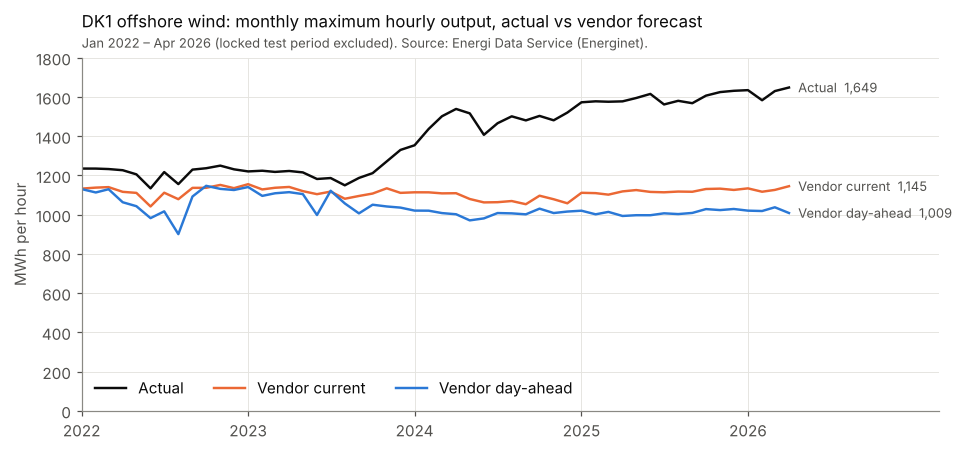

In [5]:
m = df[["actual_off", "da_off", "cur_off"]].groupby(dday.to_period("M")).max()
m.index = m.index.to_timestamp()

fig, ax = plt.subplots(figsize=(9, 4.2))
series = [("actual_off", "Actual", C["ink"]), ("cur_off", "Vendor current", C["orange"]),
          ("da_off", "Vendor day-ahead", C["blue"])]
for col, label, colour in series:
    ax.plot(m.index, m[col], color=colour, label=label)
    ax.annotate(f"{label}  {m[col].iloc[-1]:,.0f}", (m.index[-1], m[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8.5, color="#52514e")
ax.set_ylabel("MWh per hour")
ax.set_ylim(0, 1800)
ax.set_xticks(pd.date_range("2022-01-01", "2026-01-01", freq="YS"))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Y"))
ax.set_xlim(m.index[0], m.index[-1] + pd.Timedelta(days=330))
ax.set_title("DK1 offshore wind: monthly maximum hourly output, actual vs vendor forecast",
             loc="left", fontsize=11, pad=20)
ax.text(0, 1.02, "Jan 2022 – Apr 2026 (locked test period excluded). Source: Energi Data Service (Energinet).",
        transform=ax.transAxes, fontsize=8.5, color="#52514e", va="bottom")
ax.legend(loc="lower left", ncol=3)
fig.tight_layout()
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "vendor_offshore_gap.png", bbox_inches="tight")
plt.show()

**Reading.** Until late 2023 the monthly maximum of actual offshore output sits about 100 MWh above both vendor
series. From 2024 the actual maximum steps up to about 1,500 MWh and keeps rising (1,649 MWh in April 2026), while
both vendor series stay capped near 1,000–1,150 MWh — including `ForecastCurrent`, the vendor's latest update. The
gap is therefore not a weather-forecast error: the most likely explanation is that the vendor's offshore model does
not include capacity commissioned from early 2024 on. This chart is reused in the README.

## 3. Day-ahead bias by year

Mean of (vendor DA − actual), MWh per hour, by delivery year:

In [6]:
bias = pd.DataFrame({
    "total": (df.da_total - df.actual_total).groupby(dday.year).mean(),
    "onshore": (df.da_on - df.actual_on).groupby(dday.year).mean(),
    "offshore": (df.da_off - df.actual_off).groupby(dday.year).mean(),
    "mean actual total": df.actual_total.groupby(dday.year).mean(),
}).rename_axis("delivery year")
bias["total bias % of mean actual"] = 100 * bias["total"] / bias["mean actual total"]
bias.round(1)

,total,onshore,offshore,mean actual total,total bias % of mean actual
delivery year,,,,,
2022,-12.3,22.7,-35.0,1590.6,-0.8
2023,-99.0,-80.5,-17.7,1602.3,-6.2
2024,-259.8,-139.2,-120.3,1739.0,-14.9
2025,-245.6,-120.1,-125.1,1634.1,-15.0
2026,-436.4,-180.4,-256.0,2093.1,-20.8


**Reading.** The total DA bias grows from about −12 MWh (2022) to about −436 MWh (Jan–Apr 2026). The offshore part
grows with the capacity gap above (−35 → −256 MWh). The onshore part is **also** negative from 2023 on (−81 to
−180 MWh), and in 2024–2025 it is as large as the offshore part. So the offshore coverage gap explains roughly half
(2024–2025) to 60% (Jan–Apr 2026) of the total DA bias, not all of it; the cause of the onshore bias is not
diagnosed here. 2026 covers only January–April, the windiest months, so its numbers are not a full-year comparison.
The offshore-only capacity correction (step 1, notebook 02) can at most address the offshore share.

## 4. The vendor DA forecast is issued per Danish local day

A forecast issued once per delivery day shows a discontinuity where one issue's horizon ends and the next begins.
Median absolute hour-to-hour change of `da_total`, by clock hour, separately for winter (CET = UTC+1) and summer
(CEST = UTC+2):

In [7]:
loc = df.index.tz_localize("UTC").tz_convert("Europe/Copenhagen")
summer = np.array([t.dst().total_seconds() > 0 for t in loc])
step = df["da_total"].diff().abs()
rows = {}
for label, msk in [("winter", ~summer), ("summer", summer)]:
    rows[(label, "by local hour")] = step[msk].groupby(loc[msk].hour).median()
    rows[(label, "by UTC hour")] = step[msk].groupby(df.index[msk].hour).median()
jumps = pd.DataFrame(rows).loc[[21, 22, 23, 0, 1, 2]].round(0)
jumps.index.name = "step into hour"
jumps

winter                    summer            
               by local hour by UTC hour by local hour by UTC hour
step into hour                                                    
21                      72.0        58.0          62.0        52.0
22                      58.0        59.0          59.0       124.0
23                      59.0       189.0          52.0        56.0
0                      189.0        65.0         124.0        51.0
1                       65.0        67.0          56.0        50.0
2                       67.0        63.0          51.0        51.0

**Reading.** The median step into local 00:00 is about 125–190 MWh versus about 50–65 MWh at other hours, in both
seasons. In UTC the jump moves with daylight saving time (into 23:00 UTC in winter, 22:00 UTC in summer). So the
vendor issues its DA forecast per **Danish local calendar day**.

**Consequence for the project.** A "day" in this project is always the Danish local delivery day
(`windfc.cutoff.delivery_day`; 23 or 25 hours on DST change days). With UTC days, the last one (winter) or two (summer)
hours of UTC day D belong to local day D+1, whose vendor DA forecast is only issued on day D — after the 10:00 UTC
D−1 issue time. Forecasting those hours from it would be a look-ahead leak. Folds, the capacity ratio, trailing error windows and scoring all use
local delivery days.

## Summary

- Validation-era data (delivery days 2022-01-01 → 2026-04-30) is hourly-contiguous; actuals are complete, vendor DA is missing for about 1% of hours.
- From 2024 the vendor's offshore forecast (DA and current) is capped near 1,000–1,150 MWh while actual offshore peaks reach 1,500–1,650 MWh: new capacity is not covered.
- DA total bias grew from about −12 MWh (2022, −0.8% of mean output) to about −436 MWh (Jan–Apr 2026, −21%); in 2024–2026 onshore bias contributes roughly 40–55% of it (2023: 81%; 2022: opposite sign), so the offshore gap is not the whole story.
- The vendor DA changes issue at local midnight, so all day logic uses Danish local delivery days.